# Fig. 1 · 通用势与专用势的 L0–L5 量化排名（GST225）

**主张**：同一套参考数据、同一套冻结后处理参数下，9 个势函数（5 个通用势 + 4 个 GST 专用势）的相对得分与分层画像。

- **a** 总分（0–100，相对分；最佳 = 100）。斜线 = L1 门控未通过。
- **b** 分层得分热图，行顺序与 a 相同。

口径：全部指标（不剔除训练集见过的参考构型）。

In [1]:
import sys, json, glob
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image as NotebookImage, display
sys.path.insert(0, str(Path.cwd()))
from style import *

In [2]:
# ---------------- 字体设置 / fonts（唯一定义字号的地方） ----------------
FS = use_paper_fonts()          # PAPER_FONTS lives in style.py
FS_TITLE, FS_LABEL, FS_TICK   = FS['title'], FS['label'], FS['tick']
FS_LEGEND, FS_ANNOT, FS_PANEL = FS['legend'], FS['annot'], FS['panel']
FS_CBLABEL, FS_CBTICK         = FS['cbar_label'], FS['cbar_tick']

In [3]:
NAME = "fig1_ranking"
OUT = FIG_ROOT / "panels" / NAME
PREVIEW_SCALE = 0.25
# a: bars 1.75 in wide, b: heatmap 3.9 in wide; row height 2.05 in for nine rows.
# LEFT = 0.135 holds the longest model label (~0.85 in at 6 pt).
LEFT, RIGHT, BM, TM, CH = 0.135, 0.985, 0.30, 0.30, 2.05
LETTERS = "ab"

def make_layout():
    H = BM + CH + TM
    fig = plt.figure(figsize=(W2, H))
    gs = fig.add_gridspec(1, 2, left=LEFT, right=RIGHT, bottom=BM / H, top=1 - TM / H,
                          width_ratios=[1.75, 3.9], wspace=0.06)
    return fig, Slots({"a": gs[0, 0], "b": gs[0, 1]})

def panel_run(letter, draw):
    fig, slots = make_layout()
    draw(fig, slots[letter])
    group = {"axes": list(fig.axes), "texts": list(fig.texts)}
    boxes = save_matched_panels(fig, {letter: group}, OUT); plt.close(fig)
    display(NotebookImage(filename=str(OUT / f"{letter}.png"), width=int(boxes[letter].width * 600 * PREVIEW_SCALE)))

R = ranking(SHOWCASE, clean=False)
ORDER = R.order()
GATE_CLOSED = {k: bool(gate_failed(k)) for k in ORDER}
print([(lab(k), round(R.overall[k], 1)) for k in ORDER])

[('NequIP-OAM-L', 87.4), ('MACE-spec-GST-NE', 82.1), ('DPA-4.0.1-Pro', 81.9), ('NequIP-spec-GST', 80.7), ('MACE-spec-GST', 80.3), ('MACE-GST-Aging', 80.1), ('MACE-MPA-0', 76.8), ('MatterSim-5M', 72.1), ('CHGNet-0.3.0', 32.9)]


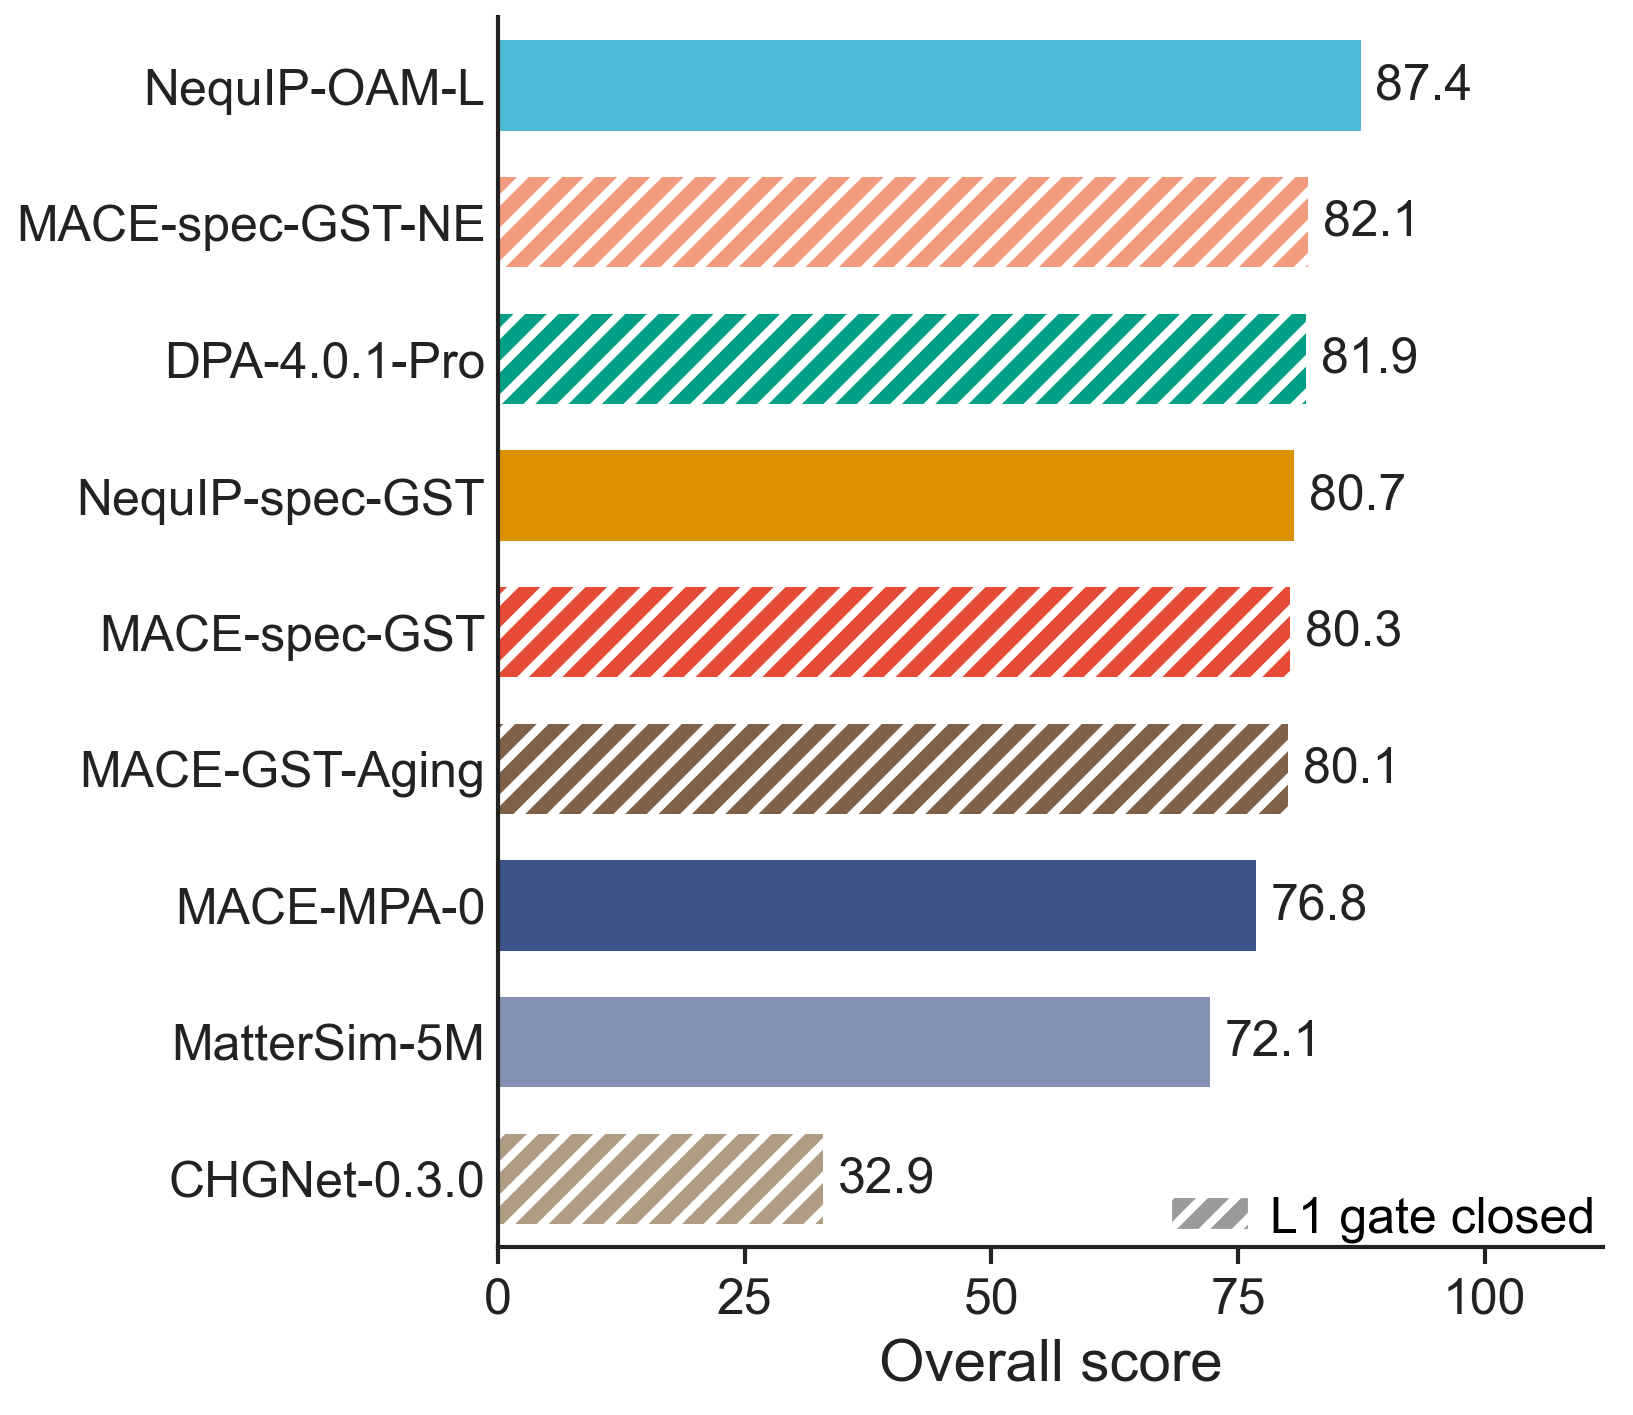

In [4]:
# ---------------- 本面板配色（独立可改，不影响其它面板） ----------------
Ca_HATCH = "#FFFFFF"     # 门控未通过的斜线
Ca_TEXT  = "#222222"
# ----------------------------------------------------------------------
def draw_a(fig, spec):
    ax = fig.add_subplot(spec)
    y = np.arange(len(ORDER))
    for i, k in enumerate(ORDER):
        b = ax.barh(i, R.overall[k], height=0.66, color=col(k), lw=0)
        if GATE_CLOSED[k]:
            b[0].set_hatch("//////"); b[0].set_edgecolor(Ca_HATCH)
        ax.text(R.overall[k] + 1.5, i, f"{R.overall[k]:.1f}", va="center", fontsize=FS_ANNOT, color=Ca_TEXT)
    ax.set_yticks(y); ax.set_yticklabels([lab(k) for k in ORDER])
    ax.set_ylim(len(ORDER) - 0.5, -0.5)
    ax.set_xlim(0, 112); ax.set_xticks([0, 25, 50, 75, 100])
    ax.set_xlabel("Overall score")
    ax.tick_params(axis="y", length=0)
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(facecolor="#9A9A9A", hatch="//////", edgecolor=Ca_HATCH, label="L1 gate closed")],
              loc="lower right", bbox_to_anchor=(1.02, -0.02))
    return ax
panel_run("a", draw_a)

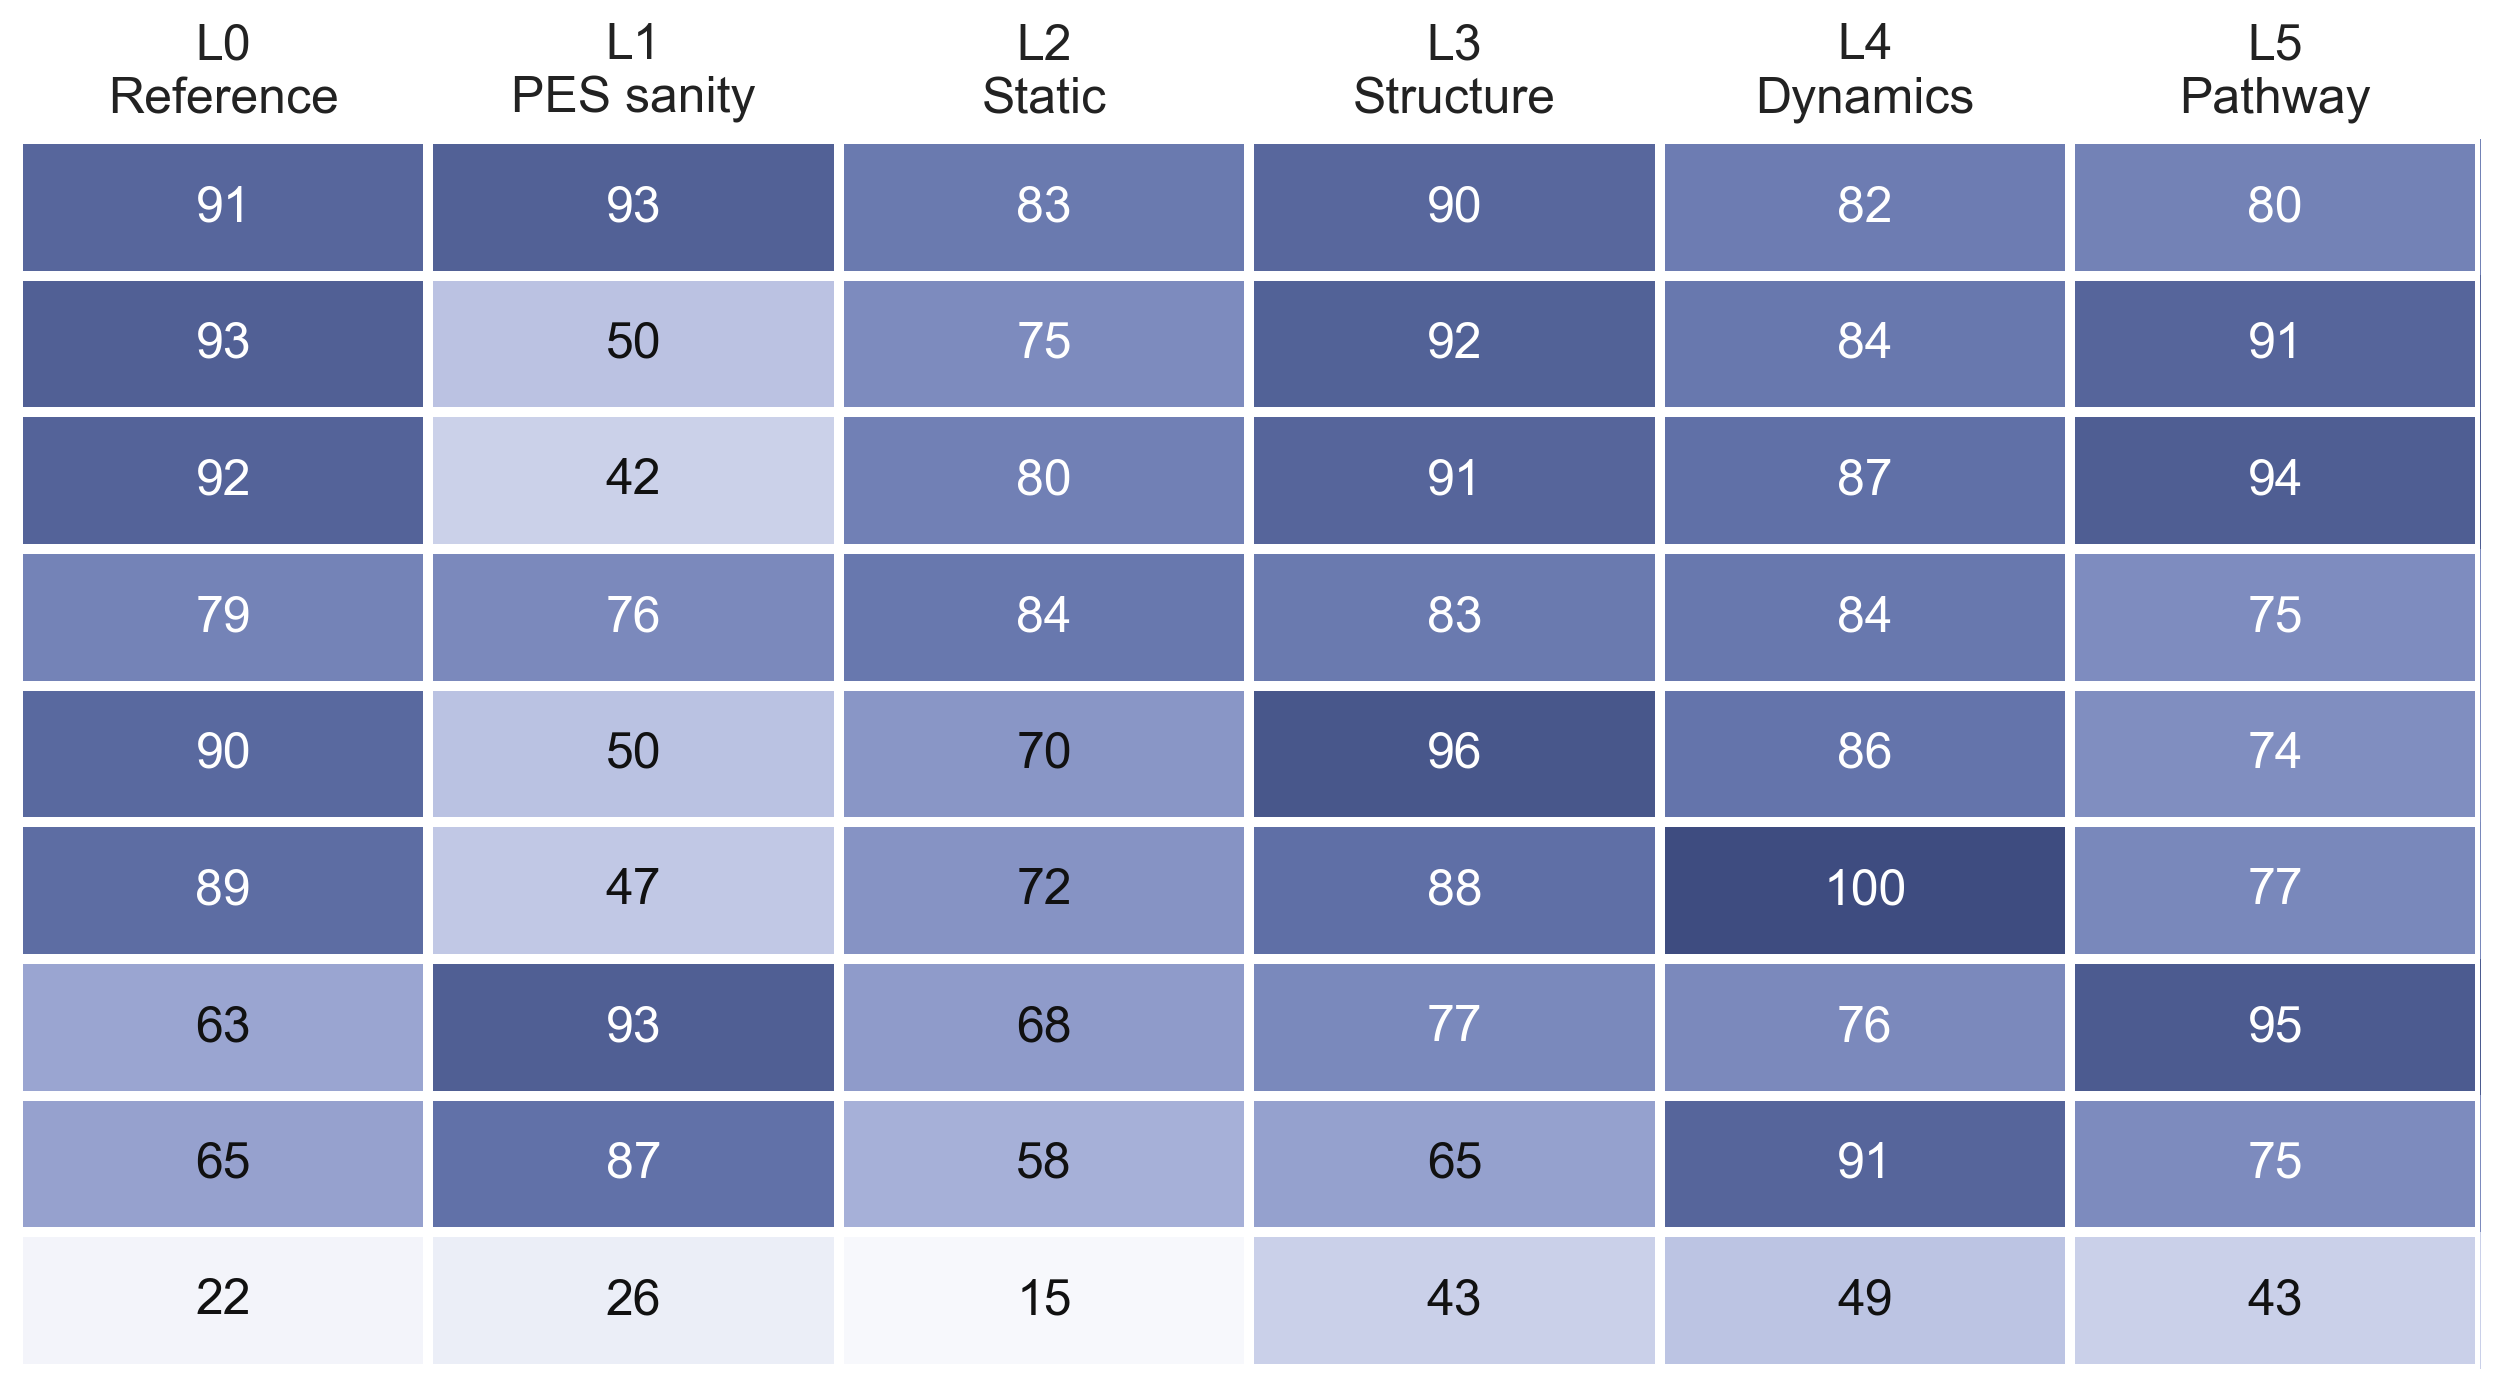

In [5]:
# ---------------- 本面板配色（独立可改，不影响其它面板） ----------------
from matplotlib.colors import LinearSegmentedColormap
Cb_CMAP = LinearSegmentedColormap.from_list("score", ["#F7F8FC", "#DEE2F2", "#C2C9E6", "#A2ACD6", "#8290C2", "#6373AA", "#3E4C80"])
Cb_INK_DARK, Cb_INK_LIGHT = "#111111", "#FFFFFF"
Cb_GRID = "#FFFFFF"
# ----------------------------------------------------------------------
def draw_b(fig, spec):
    ax = fig.add_subplot(spec)
    M = np.array([[R.level_scores[lv][k] if R.level_scores[lv][k] is not None else np.nan for lv in LEVELS] for k in ORDER])
    im = ax.imshow(M, cmap=Cb_CMAP, vmin=20, vmax=100, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M[i, j]
            if np.isfinite(v):
                ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=FS_ANNOT,
                        color=Cb_INK_LIGHT if v > 72 else Cb_INK_DARK)
    ax.set_xticks(range(len(LEVELS)))
    ax.set_xticklabels([f"{lv}\n{LEVEL_NAMES[lv]}" for lv in LEVELS])
    ax.xaxis.tick_top(); ax.tick_params(axis="x", length=0, pad=2)
    ax.set_yticks([])
    for s in ax.spines.values(): s.set_visible(False)
    ax.set_xticks(np.arange(-0.5, len(LEVELS)), minor=True); ax.set_yticks(np.arange(-0.5, len(ORDER)), minor=True)
    ax.grid(which="minor", color=Cb_GRID, lw=1.2); ax.tick_params(which="minor", length=0)
    return ax
panel_run("b", draw_b)

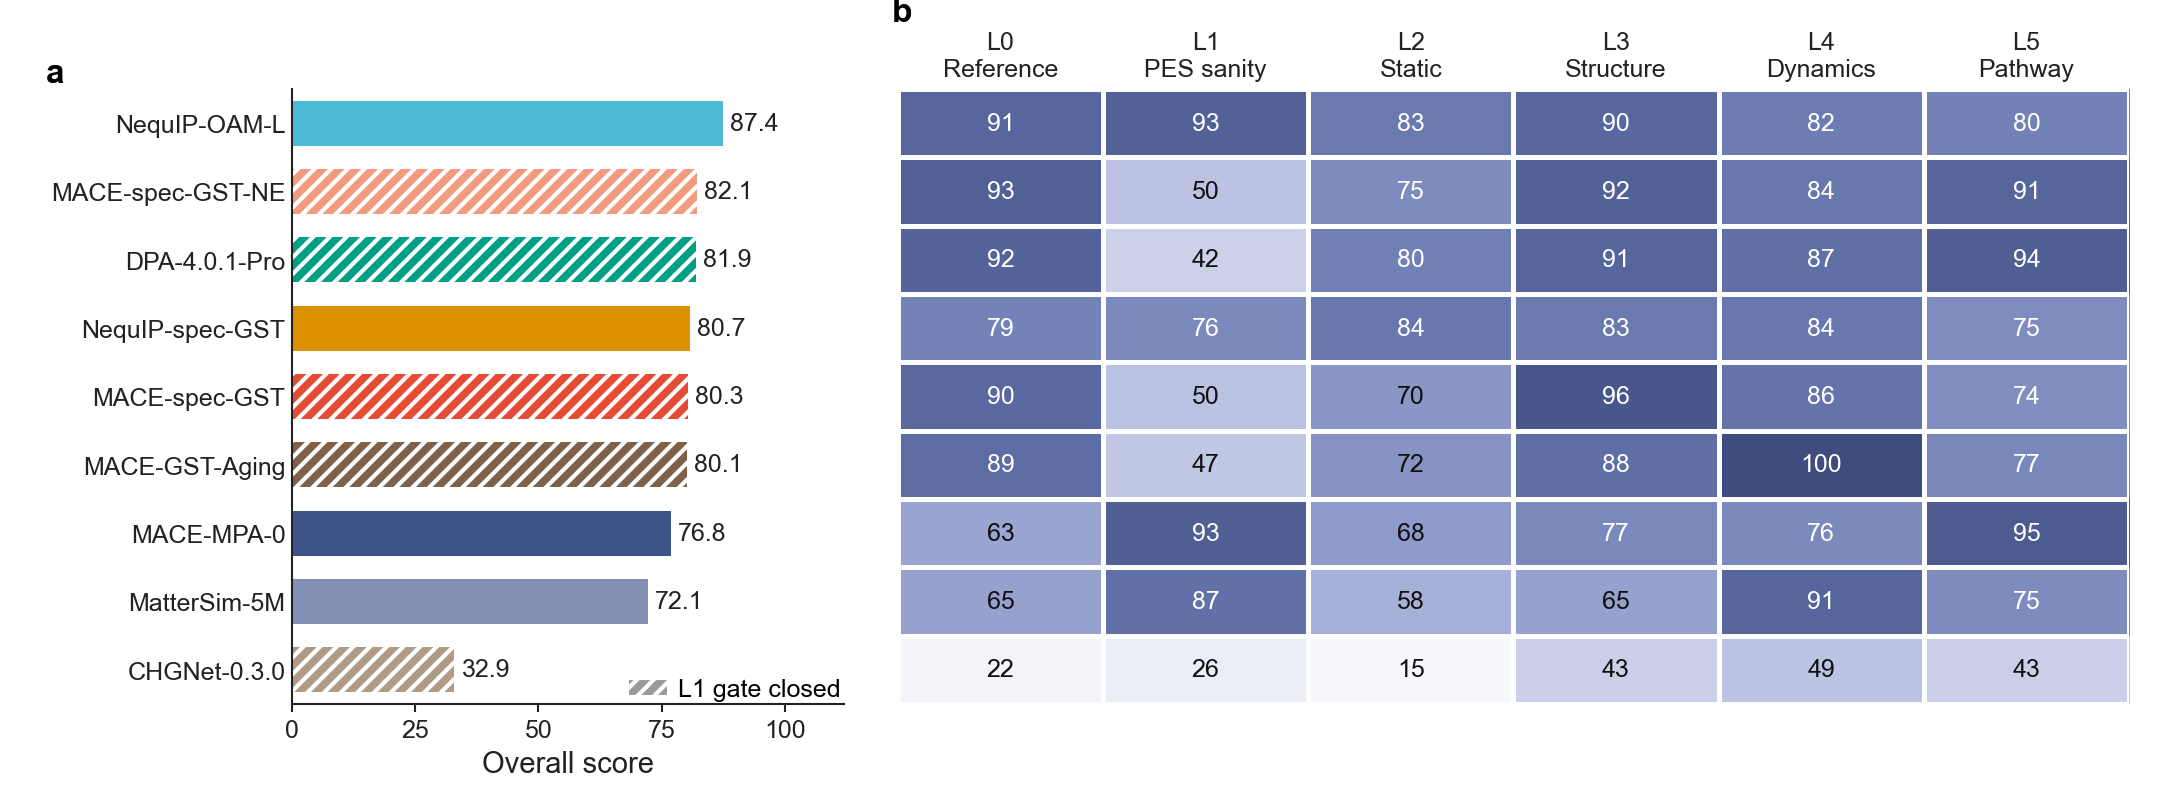

In [6]:
fig, slots = make_layout()
DRAW = {l: globals()[f"draw_{l}"] for l in LETTERS}
main_axes = {}
for l in LETTERS:
    n0 = len(fig.axes)
    ax = DRAW[l](fig, slots[l])
    main_axes[l] = ax
for l in LETTERS:
    mark(fig, main_axes[l], l, FS_PANEL)
png = export(fig, "fig1_ranking")
groups = {}
plt.close(fig)
display(NotebookImage(filename=str(png), width=900))